# HCAI 4302 – Fundamentals of Human-Centered AI Models
## Homework 2: Predicting Song Popularity
**Author:** Gemar Johnston

| Task | Topic |
|---|---|
| 1 | Exploratory data analysis |
| 2 | Predicting popularity (regression): Lasso, Ridge, Elastic Net, KNN, Decision Trees, Random Forests |
| 3 | Classifying hits (popularity > 60): Lasso feature selection, then KNN, Decision Trees, Random Forests |

**How to use:** put `dataset_simplified.csv` in the same folder as this notebook and choose *Run All*.


## 0. Setup: imports, settings and helper functions

In [ ]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso, Ridge, ElasticNet
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.tree import (DecisionTreeRegressor, DecisionTreeClassifier,
                        plot_tree, export_text)
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import mean_squared_error, r2_score, confusion_matrix

warnings.filterwarnings("ignore")          # harmless convergence warnings
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
sns.set_theme(style="whitegrid")

# ----- Settings dictated by the assignment -----
RANDOM_STATE = 42
TEST_SIZE = 0.30
LAMBDAS = [0.1, 1, 2, 3, 4, 5]            # penalty strength (sklearn calls it alpha)
L1_RATIOS = [0.1, 0.3, 0.5, 0.7, 0.9]     # Elastic Net mixing values
K_LIST = [4, 5, 6, 7]                     # KNN neighbours
DISTANCES = ["euclidean", "manhattan", "minkowski"]
DEPTHS = [2, 3, 4, 5, 6]                  # tree / forest depths
N_TREES = [50, 100, 150]                  # forest sizes
HIT_THRESHOLD = 60                        # hit  <=>  popularity > 60
LASSO_ALPHA_CLF = 0.0295                  # Lasso alpha for feature selection

# ----- My personal selection -----
MINKOWSKI_P = 3        # trick #6: p=2 would duplicate Euclidean
SCALE_TARGET = False   # keep popularity in original units so MSE is interpretable
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)


def show_fig(name):
    """Save the current figure to ./figures and display it in the notebook."""
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, name), dpi=150, bbox_inches="tight")
    plt.show()


def make_knn(kind, k, dist):
    """Build a KNN model (regressor or classifier) and a readable label.
    Centralizing this avoids repeating the Minkowski-p logic in Tasks 2 and 3."""
    cls = KNeighborsRegressor if kind == "regression" else KNeighborsClassifier
    if dist == "minkowski":
        return (cls(n_neighbors=k, metric="minkowski", p=MINKOWSKI_P),
            f"k={k}, distance=minkowski(p={MINKOWSKI_P})")
    return cls(n_neighbors=k, metric=dist), f"k={k}, distance={dist}"

# Task 1: Exploratory Data Analysis

### 1.1 Load the dataset

In [ ]:

candidates = ["dataset_simplified.csv", "dataset simplifed.csv",
            "dataset_simplifed.csv", "dataset simplified.csv"]
data_path = next((p for p in candidates if os.path.exists(p)), None)
if data_path is None:
    raise FileNotFoundError("Put dataset_simplified.csv in the same folder as this notebook.")

df_raw = pd.read_csv(data_path)
print(f"Loaded '{data_path}' -> {df_raw.shape[0]} rows x {df_raw.shape[1]} columns")
df_raw.head()

Loaded 'dataset_simplified.csv' -> 1000 rows x 21 columns


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,4267,0owIthsU5nNNPLK6MjdVOe,Dario Marianelli,Everest (Original Motion Picture Soundtrack),Someone Loves Us,55,116760,False,0.1760,0.0100,4,-27.1010,1,0.0456,0.9730,0.8540,0.0842,0.0385,83.9020,4,ambient
1,21309,6prqX1SW2MMH8hAOIzKQ3Z,Eugy;Mr Eazi,Dance For Me (Eugy X Mr Eazi),Dance For Me (Eugy X Mr Eazi),56,204173,False,0.7740,0.6850,11,-5.1400,0,0.0690,0.1540,0.0000,0.3910,0.5870,106.9820,4,dancehall
2,1799,0MAjodNUjLlzRw9hd65QiS,Los Amigos Invisibles,The New Sound of the Venezuelan Gozadera,Mango Cool,19,174293,False,0.5270,0.8830,0,-6.7990,0,0.0316,0.0204,0.7550,0.0913,0.8280,155.1350,4,afrobeat
3,84184,6ToM0uwxtPKo9CMpbPGYvM,The Doors,The Doors,Break on Through (To the Other Side),72,145866,False,0.4210,0.7510,9,-9.5840,1,0.0472,0.2000,0.0000,0.1700,0.7890,89.8390,4,psych-rock
4,8401,4wASBXZ15QVnypp0SY8Jhm,Al Green,Let's Stay Together,Let's Stay Together,31,199396,False,0.7560,0.4010,7,-10.7000,0,0.0529,0.5870,0.0114,0.0541,0.5200,101.9760,4,blues


### 1.2 Drop identifier / text columns
These are IDs or free text with unique values, so they have no predictive value and would replicate thousands of useless dummies and would render the data overrun.

In [ ]:
DROP_COLS = ["Unnamed: 0", "track_id", "artists", "album_name", "track_name"]
missing_cols = [c for c in DROP_COLS if c not in df_raw.columns]
assert not missing_cols, f"Columns not found: {missing_cols}"
df = df_raw.drop(columns=DROP_COLS)
print(f"After dropping {DROP_COLS}:\n -> {df.shape[0]} rows x {df.shape[1]} columns")

# Quick data-quality checks
print("\nTotal missing values:", int(df.isna().sum().sum()))
print("Fully duplicated rows:", int(df.duplicated().sum()))
print("\nData types:")
print(df.dtypes.to_string())

# Variables stored as numbers/booleans that are really categories!
CAT_COLS = ["explicit", "key", "mode", "time_signature", "track_genre"]
# Everything else is a genuine, proper, numeric variable (includes the target)
NUM_COLS = [c for c in df.columns if c not in CAT_COLS]

After dropping ['Unnamed: 0', 'track_id', 'artists', 'album_name', 'track_name']:
 -> 1000 rows x 16 columns

Total missing values: 0
Fully duplicated rows: 0

Data types:
popularity            int64
duration_ms           int64
explicit               bool
danceability        float64
energy              float64
key                   int64
loudness            float64
mode                  int64
speechiness         float64
acousticness        float64
instrumentalness    float64
liveness            float64
valence             float64
tempo               float64
time_signature        int64
track_genre             str


### 1.3 Summary statistics of all variables

In [ ]:
print("--- Continuous / count variables ---")
print(df[NUM_COLS].describe().T)

print("\n--- Categorical variables stored as numeric codes ---")
for col in ["explicit", "key", "mode", "time_signature"]:
    counts = df[col].value_counts().sort_index()
    share = (counts / len(df) * 100).round(1)
    print(f"\n{col}:")
    print(pd.DataFrame({"count": counts, "percent": share}).T.to_string())

print("\n--- track_genre ---")
genre_counts = df["track_genre"].value_counts()
print(f"Distinct genres: {df['track_genre'].nunique()}")
print(f"Songs per genre -> min: {genre_counts.min()}, median: {genre_counts.median():.0f}, max: {genre_counts.max()}")
print("Top 10 genres:")
print(genre_counts.head(10).to_string())

print("\nData-quality flags:")
print(f"  tempo == 0 rows          : {(df['tempo'] == 0).sum()}")
print(f"  time_signature in {{0, 1}} : {df['time_signature'].isin([0, 1]).sum()} (unusual meters)")
print(f"  share of hits (pop > {HIT_THRESHOLD}) : {(df['popularity'] > HIT_THRESHOLD).mean():.1%}")

--- Continuous / count variables ---
                      count         mean         std         min          25%          50%          75%            max
popularity       1,000.0000      38.2300     19.8495      1.0000      23.0000      40.0000      52.0000       100.0000
duration_ms      1,000.0000 229,638.2420 93,854.6748 31,186.0000 176,983.2500 215,599.5000 266,616.5000 1,194,057.0000
danceability     1,000.0000       0.5715      0.1677      0.0000       0.4640       0.5830       0.6912         0.9330
energy           1,000.0000       0.6532      0.2511      0.0000       0.4775       0.7065       0.8612         1.0000
loudness         1,000.0000      -8.1044      4.7008    -37.4630      -9.8260      -7.1275      -5.0505         0.2170
speechiness      1,000.0000       0.0801      0.0951      0.0000       0.0350       0.0476       0.0800         0.9450
acousticness     1,000.0000       0.2964      0.3196      0.0000       0.0126       0.1570       0.5338         0.9960
instrumenta

None

### 1.4 Histogram of track popularity

Skewness = 0.069, excess kurtosis = -0.659


None

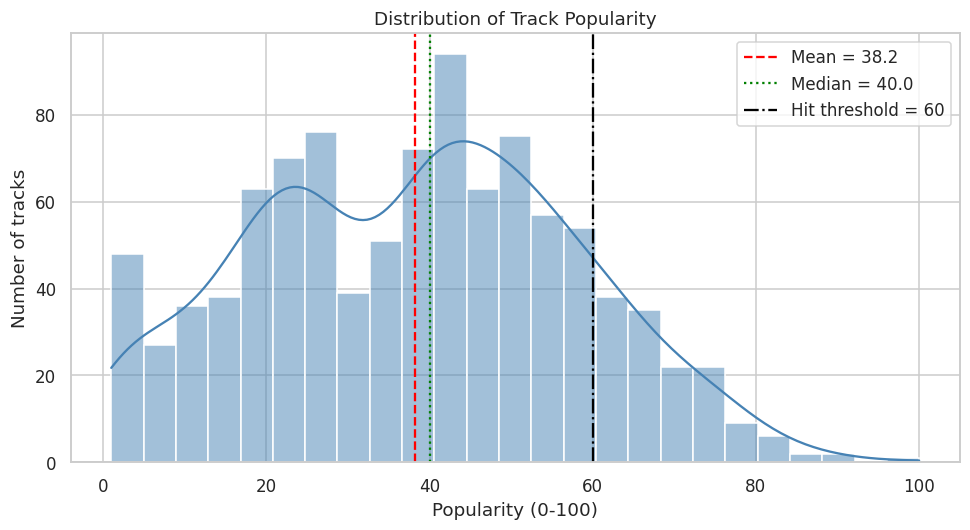

In [ ]:
plt.figure(figsize=(9, 5))
sns.histplot(df["popularity"], bins=25, kde=True, color="steelblue")
plt.axvline(df["popularity"].mean(), color="red", ls="--", label=f"Mean = {df['popularity'].mean():.1f}")
plt.axvline(df["popularity"].median(), color="green", ls=":", label=f"Median = {df['popularity'].median():.1f}")
plt.axvline(HIT_THRESHOLD, color="black", ls="-.", label=f"Hit threshold = {HIT_THRESHOLD}")
plt.title("Distribution of Track Popularity")
plt.xlabel("Popularity (0-100)")
plt.ylabel("Number of tracks")
plt.legend()
show_fig("task1_popularity_histogram.png")

print(f"Skewness = {df['popularity'].skew():.3f}, excess kurtosis = {df['popularity'].kurt():.3f}")

### 1.5 Correlation heatmap of the numeric variables
The 0/1 `explicit` flag is included (correlating a 0/1 variable is fine). `key`, `mode` and `time_signature` are numeric codes and are included because the assignment calls for *all numeric variables*, but maintain that `key` is nominal.

Strongest pairwise correlations:
           var_1            var_2    corr
        loudness           energy  0.7702
    acousticness           energy -0.7298
    acousticness         loudness -0.5785
         valence     danceability  0.4668
instrumentalness         loudness -0.3548
        explicit      speechiness  0.3160
           tempo           energy  0.2602
         valence instrumentalness -0.2566

Correlation of every variable with popularity:
instrumentalness   -0.1786
duration_ms        -0.1011
energy             -0.0896
danceability        0.0875
speechiness        -0.0787
acousticness        0.0452
liveness           -0.0402
loudness            0.0314
key                -0.0123
valence            -0.0115
mode               -0.0092
time_signature      0.0061
tempo               0.0029
explicit           -0.0002


None

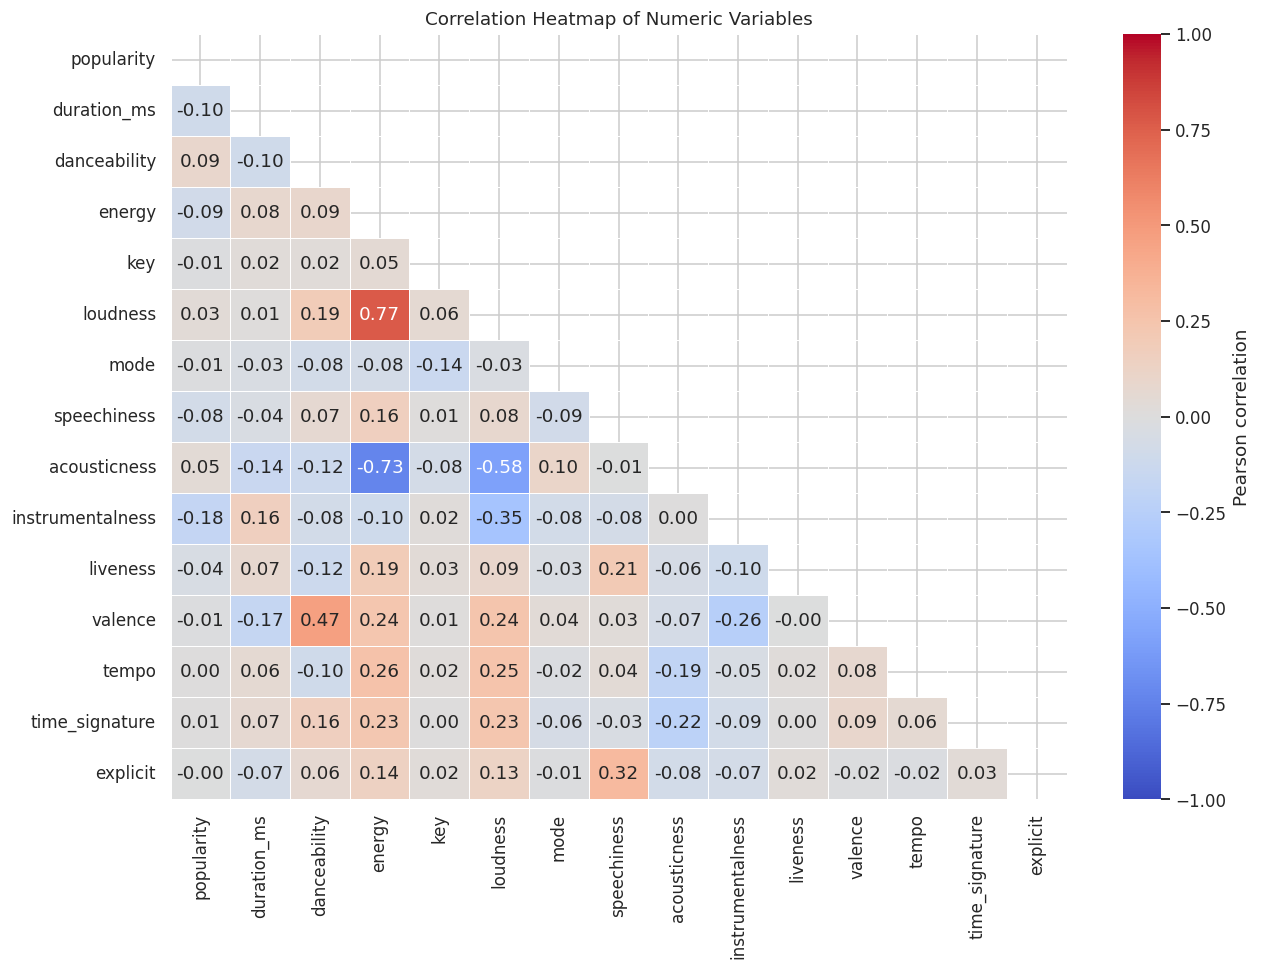

In [ ]:
df_corr = df.select_dtypes(include="number").copy()
df_corr["explicit"] = df["explicit"].astype(int)
corr = df_corr.corr()

plt.figure(figsize=(12, 9))
mask = np.triu(np.ones_like(corr, dtype=bool))       # hide the redundant upper half
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, linewidths=0.5, cbar_kws={"label": "Pearson correlation"})
plt.title("Correlation Heatmap of Numeric Variables")
show_fig("task1_correlation_heatmap.png")

# Strongest relationships, so the interpretation is data-driven
pairs = (corr.where(np.tril(np.ones(corr.shape), k=-1).astype(bool)).stack().reset_index())
pairs.columns = ["var_1", "var_2", "corr"]
pairs["abs_corr"] = pairs["corr"].abs()
print("Strongest pairwise correlations:")
print(pairs.sort_values("abs_corr", ascending=False).head(8).drop(columns="abs_corr").to_string(index=False))
print("\nCorrelation of every variable with popularity:")
print(corr["popularity"].drop("popularity").sort_values(key=abs, ascending=False).to_string())

### 1.6 Interpretation of Task 1


**Summary Statistics**

* The available sample has 1,000 tracks from 114 genres (between 2 and 18 songs per genre,
  median 9). There are no missing values and no fully duplicated rows.
* Popularity of the songs averages 38.2 (median 40, sd 19.8) and spans 1 to 100. Mean and
  median are close, thus the variable is roughly symmetric.
* Several audio features are strongly skewed. Duration has a median of about
  3.6 minutes but a maximum of about 20 minutes (right tail). Speechiness
  (median 0.048 vs mean 0.080) and liveness (0.133 vs 0.209) are right-skewed.
  Instrumentalness has a median of essentially 0 but a mean of 0.17: most songs
  have vocals and a minority are almost purely instrumental. Energy is
  left-skewed (median 0.71 > mean 0.65), so the sample leans towards energetic
  music. Loudness has a few extremely quiet tracks (minimum about -37 dB).
* Categorical structure: only 8.2% of tracks are explicit, 64% are in a major
  key (mode = 1), 89% are in 4/4 time, and key 7 is the most common (13%).
  Time signatures 0 and 1 (14 rows) and tempo = 0 (2 rows) are not valid
  musical values, so they look like measurement errors from the audio
  analysis. I included them due to the fact that the assignment directly requires all 1,000 rows.


**Histogram Of Popularity**

* The distribution is wide and fairly flat: skewness is about 0.07 (almost
  symmetric) and excess kurtosis is about -0.66 (flatter than a normal curve).
  There is no single dominant peak. Most tracks fall between 20 and 60.

* The two tails are very different in practice. About 59 songs have popularity
  of 5 or less, while only 14 songs reach 80 or more. Just 13.7% of songs are
  above the hit threshold of 60. Very popular songs are rare, so (a) models
  will tend to predict values near the middle and under-predict the top, and
  (b) the hit classification problem in Task 3 is imbalanced (about 86/14).


**Correlation Heatmap**

* The strongest relationships are the predictors, not with popularity:
  loudness-energy (+0.77), acousticness-energy (-0.73), acousticness-loudness
  (-0.58), valence-danceability (+0.47), instrumentalness-loudness (-0.35) and
  explicit-speechiness (+0.32). Loud tracks are energetic and non-acoustic,
  and happy tracks are danceable. These make sense because the features are
  derived from the same audio signal.

* Those overlapping predictors create multicollinearity, which makes plain
  linear regression coefficients unstable. That is a positive motivation for the
  penalized models (Ridge, Lasso, Elastic Net) in Task 2.

* Every correlation with popularity is weak. The largest is instrumentalness
  (-0.18): instrumental tracks tend to be less popular. Next are duration
  (-0.10), energy (-0.09), danceability (+0.09) and speechiness (-0.08). Tempo,
  key, mode, time signature and explicit are all essentially zero (explicit
  tracks have the same average popularity as non-explicit ones, about 38.2).

* Caveats: The heatmap only shows LINEAR, PAIRWISE relationships, and key is
  a nominal code (the correlation with key is not meaningful). Genre is not in
  the heatmap, but it looks important: some genres average below 10 (romance,
  iranian) and others above 60 (metal, house, pop-film), although each genre
  has only about 9 songs so those averages are noisy. Overall, I would expect
  audio features alone to predict popularity poorly as it stands.

# Task 2: Predicting Popularity with Regularization

### 2.1 Dummy variables and standardization
`get_dummies` with `drop_first=True` removes one reference level per variable. `dtype=float` gives 0.0/1.0 instead of booleans. Only the numeric predictors are standardized; the dummies stay 0/1.

In [ ]:
df_model = pd.get_dummies(df, columns=CAT_COLS, drop_first=True, dtype=float)

cols_to_scale = NUM_COLS if SCALE_TARGET else [c for c in NUM_COLS if c != "popularity"]
df_model[cols_to_scale] = StandardScaler().fit_transform(df_model[cols_to_scale])

print(f"Model dataframe shape: {df_model.shape}  (expected (1000, 141))")
assert df_model.shape == (1000, 141), "Shape is not 1000 x 141 - check the dummies!"
print(f" - standardized columns: {len(cols_to_scale)}")
print(f" - dummy columns       : {df_model.shape[1] - len(NUM_COLS)}")
print(f" - target + predictors : 1 + {df_model.shape[1] - 1}")

Model dataframe shape: (1000, 141)  (expected (1000, 141))
 - standardized columns: 10
 - dummy columns       : 130
 - target + predictors : 1 + 140


None

### 2.2 Train / test split (exactly as specified)

In [ ]:
X = df_model.drop(columns="popularity")
y = df_model["popularity"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")

Train: (700, 140), Test: (300, 140)


None

### 2.3 Fit every model in the grid
* Lasso and Ridge: λ ∈ [0.1, 1, 2, 3, 4, 5]
* Elastic Net: the same λ values × 5 `l1_ratio` values (30 models)
* KNN: k ∈ [4, 5, 6, 7] × 3 distances (12 models)
* Trees: depths 2–6 (5 models)
* Random forests: depths 2–6 × 50/100/150 trees (15 models)

In [ ]:
results = []      # one row per fitted model.
fitted = {}       # keep fitted objects so the best can be reused.


def evaluate_regressor(label, params, model):
    """Fit, then store test MSE / R2 (and train R2 to spot overfitting)."""
    model.fit(X_train, y_train)
    pred_test, pred_train = model.predict(X_test), model.predict(X_train)
    results.append({
        "Model": label, "Hyperparameters": params,
        "Test_MSE": mean_squared_error(y_test, pred_test),
        "Test_R2": r2_score(y_test, pred_test),
        "Train_R2": r2_score(y_train, pred_train),
    })
    fitted[(label, params)] = model


for lam in LAMBDAS:
    evaluate_regressor("Lasso", f"lambda={lam}", Lasso(alpha=lam, max_iter=10000, random_state=RANDOM_STATE))
    evaluate_regressor("Ridge", f"lambda={lam}", Ridge(alpha=lam, random_state=RANDOM_STATE))
    for l1 in L1_RATIOS:
        evaluate_regressor("ElasticNet", f"lambda={lam}, l1_ratio={l1}",
                        ElasticNet(alpha=lam, l1_ratio=l1, max_iter=10000, random_state=RANDOM_STATE))

for k in K_LIST:
    for dist in DISTANCES:
        model, desc = make_knn("regression", k, dist)
        evaluate_regressor("KNN", desc, model)

for d in DEPTHS:
    evaluate_regressor("DecisionTree", f"max_depth={d}",
                    DecisionTreeRegressor(max_depth=d, random_state=RANDOM_STATE))
    for n in N_TREES:
        evaluate_regressor("RandomForest", f"max_depth={d}, n_estimators={n}",
                        RandomForestRegressor(max_depth=d, n_estimators=n,
                            random_state=RANDOM_STATE, n_jobs=-1))

res_df = pd.DataFrame(results).sort_values("Test_MSE").reset_index(drop=True)
print(f"Total models fitted: {len(res_df)}")
print(res_df["Model"].value_counts().to_string())

# Baseline: This line will always predict the training mean (R2 ~ 0). A proper model must best it.
baseline_mse = mean_squared_error(y_test, np.full(len(y_test), y_train.mean()))
print(f"\nBaseline (predict the training mean) test MSE = {baseline_mse:.2f}")

Total models fitted: 74
Model
ElasticNet      30
RandomForest    15
KNN             12
Ridge            6
Lasso            6
DecisionTree     5

Baseline (predict the training mean) test MSE = 396.56


None

### 2.4 Top 5 models by test MSE (with R²)

In [ ]:
# How the penalized regressions act as lambda grows (ElasticNet: best l1_ratio)
lin = res_df[res_df.Model.isin(["Lasso", "Ridge", "ElasticNet"])].copy()
lin["lambda"] = lin.Hyperparameters.str.extract(r"lambda=([\d.]+)")[0].astype(float)
print("Test MSE of penalized regressions by lambda:")
print(lin.pivot_table(index="Model", columns="lambda", values="Test_MSE", aggfunc="min").to_string())
for lam in (0.1, 1):
    n_kept = int((fitted[("Lasso", f"lambda={lam}")].coef_ != 0).sum())
    print(f"Lasso (lambda={lam}) keeps {n_kept} of {X.shape[1]} predictors")

print("\n--- TOP 5 MODELS BY TEST MSE (lower is better) ---")
top5 = res_df.head(5).copy()
top5.index = np.arange(1, 6)
print(top5.to_string())

print("\nBest model of each family (by test MSE):")
print(res_df.groupby("Model").first()[["Hyperparameters", "Test_MSE", "Test_R2"]]
    .sort_values("Test_MSE").to_string())

Test MSE of penalized regressions by lambda:
lambda       0.1000   1.0000   2.0000   3.0000   4.0000   5.0000
Model                                                           
ElasticNet 338.8139 377.4292 383.8248 386.9646 388.8307 390.1824
Lasso      316.7924 377.0167 386.8555 395.7553 396.5641 396.5641
Ridge      271.8714 262.1524 266.7792 273.4151 279.9726 286.0074
Lasso (lambda=0.1) keeps 51 of 140 predictors
Lasso (lambda=1) keeps 5 of 140 predictors

--- TOP 5 MODELS BY TEST MSE (lower is better) ---
   Model Hyperparameters  Test_MSE  Test_R2  Train_R2
1  Ridge        lambda=1  262.1524   0.3388    0.4320
2  Ridge        lambda=2  266.7792   0.3271    0.4131
3  Ridge      lambda=0.1  271.8714   0.3143    0.4442
4  Ridge        lambda=3  273.4151   0.3104    0.3941
5  Ridge        lambda=4  279.9726   0.2939    0.3765

Best model of each family (by test MSE):
                            Hyperparameters  Test_MSE  Test_R2
Model                                                       

None

### 2.5 Best decision tree with depth 3

Depth-3 regression tree: Test MSE = 375.01, Test R2 = 0.0542

|--- energy <= 0.80
|   |--- track_genre_house <= 0.50
|   |   |--- track_genre_romance <= 0.50
|   |   |   |--- value: [41.01]
|   |   |--- track_genre_romance >  0.50
|   |   |   |--- value: [6.83]
|   |--- track_genre_house >  0.50
|   |   |--- speechiness <= -0.44
|   |   |   |--- value: [61.50]
|   |   |--- speechiness >  -0.44
|   |   |   |--- value: [75.17]
|--- energy >  0.80
|   |--- instrumentalness <= -0.53
|   |   |--- danceability <= 1.45
|   |   |   |--- value: [34.29]
|   |   |--- danceability >  1.45
|   |   |   |--- value: [61.33]
|   |--- instrumentalness >  -0.53
|   |   |--- track_genre_progressive-house <= 0.50
|   |   |   |--- value: [24.43]
|   |   |--- track_genre_progressive-house >  0.50
|   |   |   |--- value: [57.33]



None

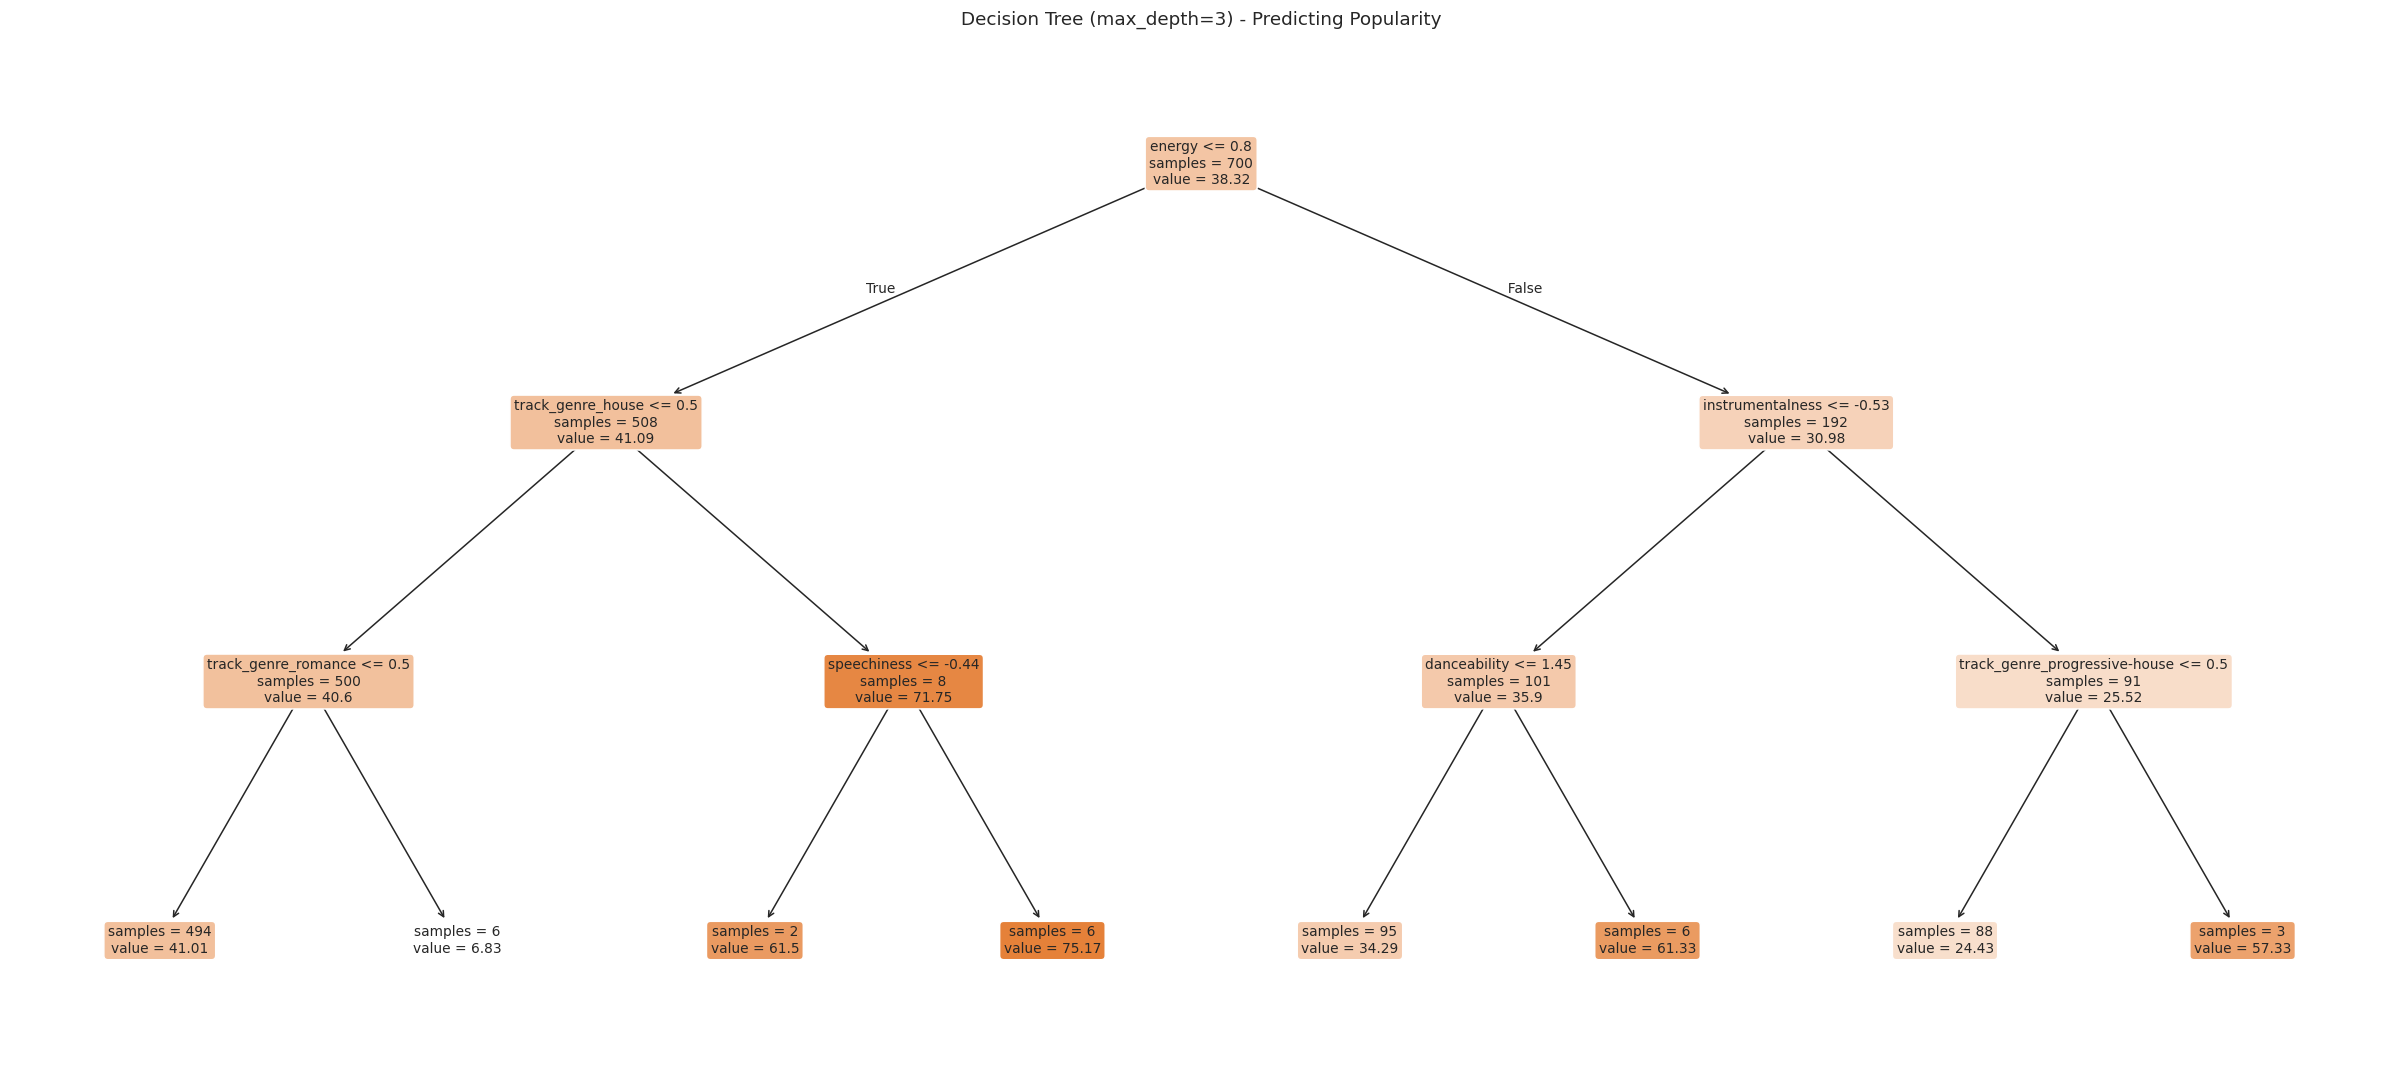

In [ ]:
tree3 = fitted[("DecisionTree", "max_depth=3")]
row = res_df[(res_df.Model == "DecisionTree") & (res_df.Hyperparameters == "max_depth=3")].iloc[0]
print(f"Depth-3 regression tree: Test MSE = {row.Test_MSE:.2f}, Test R2 = {row.Test_R2:.4f}\n")
print(export_text(tree3, feature_names=list(X.columns), decimals=2))

plt.figure(figsize=(22, 10))
plot_tree(tree3, feature_names=list(X.columns), filled=True, rounded=True,
        fontsize=9, precision=2, impurity=False)
plt.title("Decision Tree (max_depth=3) - Predicting Popularity")
show_fig("task2_tree_depth3.png")

#### Interpretation of the depth-3 tree

How to read the tree (features are standardized, so 0 = average). A leaf value is
the average popularity of the training songs that end up in that leaf.
* Root split: energy <= 0.80 (roughly energy <= 0.85 on the original scale). There for,
  the first and most informative split separates very energetic songs from
  the rest.

* Lower-energy branch (the large majority of songs): songs that are not house
  and not romance are predicted at about 41 (close to the overall mean of 38).
  Romance songs are predicted at about 7 (very unpopular), while house songs
  are predicted at 61 to 75 (very popular), depending on speechiness (house
  songs with speechiness above -0.44 average about 75).

* High-energy branch: if the song is vocal (instrumentalness <= -0.53, i.e.
  practically zero), the prediction is about 34, rising to about 61 for extremely
  danceable songs (danceability > 1.45). If the song has some instrumental
  content, the prediction drops to about 24, except for progressive house
  (about 57).

* Take-aways and notes: (1) energy is the main audio driver, and it acts in a
  non-linear way with instrumentalness and danceability; (2) genre indicators
  (house, romance, progressive-house) create the extreme leaves, but each
  genre has only a handful of songs. The plot shows the leaves contain only
  2, 6, 6, 3 and 6 training songs (versus 494 in the main leaf), thus they are
  based on a small amount of observations and are likely to be noise or over-fitting; (3) the tree has
  a test R2 of only 0.054, so depth 3 is too shallow to capture much and the
  result should be treated as a simple description and not a reliable predictor.

### 2.6 Feature importance of the best random forest

Best random forest: max_depth=6, n_estimators=150 (Test MSE = 352.14, R2 = 0.1118)

Top 15 feature importances (they sum to 1 over all 140 features):
energy                   0.1361
acousticness             0.0863
instrumentalness         0.0778
tempo                    0.0761
speechiness              0.0715
duration_ms              0.0696
danceability             0.0649
valence                  0.0558
loudness                 0.0538
liveness                 0.0442
track_genre_romance      0.0344
track_genre_house        0.0292
track_genre_pop          0.0157
track_genre_latin        0.0139
track_genre_honky-tonk   0.0134

Share of total importance held by the top 15: 84.3%


None

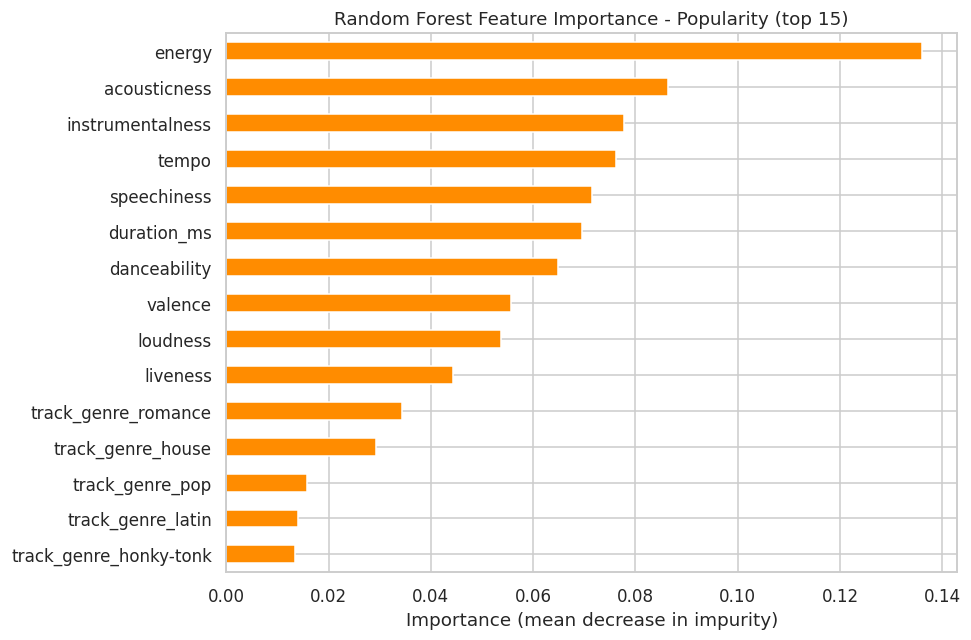

In [ ]:
best_rf_row = res_df[res_df.Model == "RandomForest"].iloc[0]
best_rf = fitted[("RandomForest", best_rf_row.Hyperparameters)]
print(f"Best random forest: {best_rf_row.Hyperparameters} "
      f"(Test MSE = {best_rf_row.Test_MSE:.2f}, R2 = {best_rf_row.Test_R2:.4f})\n")

imp = pd.Series(best_rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print("Top 15 feature importances (they sum to 1 over all 140 features):")
print(imp.head(15).to_string())
print(f"\nShare of total importance held by the top 15: {imp.head(15).sum():.1%}")

plt.figure(figsize=(9, 6))
imp.head(15).sort_values().plot(kind="barh", color="darkorange")
plt.title("Random Forest Feature Importance - Popularity (top 15)")
plt.xlabel("Importance (mean decrease in impurity)")
show_fig("task2_rf_feature_importance.png")

#### Interpretation of the Task 2 models and the forest


**Model Comparison**

* The five best models are all RIDGE regressions (lambda = 1, 2, 0.1, 3, 4).
  The best, Ridge with lambda = 1, has a test MSE of 262.2 (RMSE of about 16
  popularity points) and R2 = 0.34, compared with a baseline MSE of 396.6 for
  always predicting the mean. Training R2 (0.43) is above test R2 (0.34), so
  there is mild overfitting but nothing severe.
* Why Ridge wins: the predictors are 140 columns, mostly sparse genre dummies
  that each carry a small effect, plus correlated audio features. Ridge keeps
  all of them and shrinks them, which suits this "many small effects" setting.
  Lasso removes variables: with lambda = 0.1 it keeps 51 predictors (R2 = 0.20),
  with lambda = 1 only 5, and from lambda = 4 upwards it removes everything and
  just predicts the mean (MSE = 396.6, the baseline). Elastic Net sits between
  the two and prefers l1_ratio = 0.9 with the smallest lambda, i.e. the
  weakest penalty, meaning that shrinking further hurt.
* The non-linear models did worse than Ridge: best random forest (depth 6,
  150 trees) MSE = 352.1 (R2 = 0.11), best KNN (k = 7, Manhattan) MSE = 354.0
  (R2 = 0.11) and the depth-3 tree MSE = 375.0 (R2 = 0.05). With only 700
  training rows and 140 mostly binary columns, there are about 6 training songs
  per genre, so trees and neighbours have little data to learn genre effects,
  and KNN distances are dominated by the dummy columns. Ridge borrows strength
  across all rows through its linear structure.
* Overall, even the best model leaves about 66% of the variance unexplained.
  Popularity depends on things that are not in this data (artist fame,
  marketing, release date, playlists).
* The best way to do this would be to cross reference the file. 


**Random Forest Feature Importance**

* The ten audio variables hold about 74% of the total importance. Energy is
  first (0.136), followed by acousticness, instrumentalness, tempo, speechiness,
  duration, danceability, valence, loudness and liveness (all between 0.04 and
  0.09). This agrees with the tree, where energy was the root split.

* Individual genre dummies have small importances each (romance 0.034 and
  house 0.029 lead), because a genre is split into a single 0/1 column applying
  to few songs. Together the genre dummies still matter (Ridge exploits them).

# Caution: impurity-based importance favours continuous variables, which offer 
# many possible split points, over binary dummies. Tempo ranking 4th, even
# though its correlation with popularity is about 0, is a sign that some of
# this importance is noise fitting. Importance shows what the forest USES, not
# a causal effect and not the direction of the effect.

# Task 3: Classification – Predicting Hits

### 3.1 Create the `hit` dummy and split the data
The label comes from the **original** popularity (trick #5), strictly greater than 60. `popularity` is removed from the predictors (trick #4).

In [ ]:
hit = (df_raw["popularity"] > HIT_THRESHOLD).astype(int)
print(f"Hits (1): {hit.sum()} | Non-hits (0): {(hit == 0).sum()} | hit rate = {hit.mean():.1%}")

X_clf = df_model.drop(columns="popularity")
assert "popularity" not in X_clf.columns          # No leak indicated. It is important to check for these.

Xc_train, Xc_test, yc_train, yc_test = train_test_split(X_clf, hit, test_size=0.30, random_state=42)
# Same n and same random_state => identical rows to Task 2 (verified):
assert (Xc_train.index == X_train.index).all() and (Xc_test.index == X_test.index).all()

baseline_acc = 1 - yc_test.mean()
print(f"\nBaseline accuracy of always predicting 'not a hit' (test set): {baseline_acc:.3f}")
print("-> accuracy must beat this number to mean anything.")

Hits (1): 137 | Non-hits (0): 863 | hit rate = 13.7%

Baseline accuracy of always predicting 'not a hit' (test set): 0.860
-> accuracy must beat this number to mean anything.


None

### 3.2 Lasso (α = 0.0295) for feature selection
Fit on the **training** data only. Coefficients shrunk exactly to zero are dropped.

In [ ]:
lasso_sel = Lasso(alpha=LASSO_ALPHA_CLF, max_iter=10000, random_state=RANDOM_STATE)
lasso_sel.fit(Xc_train, yc_train)
coefs = pd.Series(lasso_sel.coef_, index=X_clf.columns)
selected = coefs[coefs != 0].index.tolist()

print(f"Lasso (alpha={LASSO_ALPHA_CLF}) kept {len(selected)} of {X_clf.shape[1]} features:")
print(coefs[coefs != 0].sort_values(key=abs, ascending=False).to_string())
if not selected:
    raise ValueError("Lasso removed every feature; lower alpha.")

Xs_train, Xs_test = Xc_train[selected], Xc_test[selected]

Lasso (alpha=0.0295) kept 3 of 140 features:
instrumentalness   -0.0146
liveness           -0.0043
danceability        0.0031


### 3.3 Fit KNN, decision trees and random forests (same grids as Task 2)
Metrics derived from the confusion matrix: accuracy, error rate, precision, recall (sensitivity), specificity, F1 and balanced accuracy. `CV_Avg_Acc` is the 5-fold cross-validated accuracy on the training data.

In [ ]:
clf_results, clf_fitted = [], {}


def confusion_metrics(y_true, y_pred):
    """Basic performance indicators derived from the confusion matrix."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    safe = lambda a, b: a / b if b > 0 else 0.0        # avoid division by zero
    precision = safe(tp, tp + fp)                       # of predicted hits, how many are real
    recall = safe(tp, tp + fn)                          # sensitivity (true-positive rate)
    specificity = safe(tn, tn + fp)                     # true-negative rate
    total = tp + tn + fp + fn
    return {"TN": tn, "FP": fp, "FN": fn, "TP": tp,
            "Accuracy": (tp + tn) / total, "Error_rate": (fp + fn) / total,
            "Precision": precision, "Recall": recall, "Specificity": specificity,
            "F1": safe(2 * precision * recall, precision + recall),
            "Balanced_Acc": (recall + specificity) / 2}


def evaluate_classifier(label, params, model):
    model.fit(Xs_train, yc_train)
    row = {"Model": label, "Hyperparameters": params}
    row.update(confusion_metrics(yc_test, model.predict(Xs_test)))
    row["CV_Avg_Acc"] = cross_val_score(model, Xs_train, yc_train, cv=5, scoring="accuracy").mean()
    clf_results.append(row)
    clf_fitted[(label, params)] = model


for k in K_LIST:
    for dist in DISTANCES:
        model, desc = make_knn("classification", k, dist)
        evaluate_classifier("KNN", desc, model)

for d in DEPTHS:
    evaluate_classifier("DecisionTree", f"max_depth={d}",
                        DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE))
    for n in N_TREES:
        evaluate_classifier("RandomForest", f"max_depth={d}, n_estimators={n}",
                            RandomForestClassifier(max_depth=d, n_estimators=n,
                                                random_state=RANDOM_STATE, n_jobs=-1))

# Ties in accuracy are common and I break them with the CV accuracy.
clf_df = (pd.DataFrame(clf_results).sort_values(["Accuracy", "CV_Avg_Acc"], ascending=False)
        .reset_index(drop=True))
print(f"Total classifiers fitted: {len(clf_df)}")

Total classifiers fitted: 32


None

### 3.4 Top 5 models by accuracy, with confusion-matrix indicators

In [ ]:
print("--- TOP 5 MODELS BY TEST ACCURACY (ties broken by 5-fold CV accuracy) ---")
top5c = clf_df.head(5).copy()
top5c.index = np.arange(1, 6)
print(top5c[["Model", "Hyperparameters", "Accuracy", "CV_Avg_Acc"]].to_string())

print("\nConfusion-matrix based indicators for those 5 models:")
print(top5c[["Model", "Hyperparameters", "TN", "FP", "FN", "TP", "Error_rate",
        "Precision", "Recall", "Specificity", "F1", "Balanced_Acc"]].to_string())

# A good number of models tie at the baseline because they never predict a hit (Recall = 0).
# Also, rank by F1 to see which models actually DETECT hits.
print("\n--- SUPPLEMENT: TOP 5 MODELS BY F1 (do they actually detect hits?) ---")
top5f1 = clf_df.sort_values(["F1", "Accuracy"], ascending=False).head(5).copy()
top5f1.index = np.arange(1, 6)
print(top5f1[["Model", "Hyperparameters", "Accuracy", "TN", "FP", "FN", "TP",
        "Precision", "Recall", "Specificity", "F1"]].to_string())
print(f"\nModels that never predict a hit (TP = 0): {int((clf_df['TP'] == 0).sum())} of {len(clf_df)}")

print("\nBest model of each family (by test accuracy):")
print(clf_df.groupby("Model").first()[["Hyperparameters", "Accuracy", "Precision", "Recall",
                        "Specificity", "F1"]].sort_values("Accuracy", ascending=False).to_string())

--- TOP 5 MODELS BY TEST ACCURACY (ties broken by 5-fold CV accuracy) ---
          Model                Hyperparameters  Accuracy  CV_Avg_Acc
1  RandomForest   max_depth=2, n_estimators=50    0.8600      0.8643
2  RandomForest  max_depth=2, n_estimators=100    0.8600      0.8643
3  RandomForest  max_depth=2, n_estimators=150    0.8600      0.8643
4  RandomForest   max_depth=3, n_estimators=50    0.8600      0.8643
5  RandomForest  max_depth=3, n_estimators=100    0.8600      0.8643

Confusion-matrix based indicators for those 5 models:
          Model                Hyperparameters   TN  FP  FN  TP  Error_rate  Precision  Recall  Specificity     F1  Balanced_Acc
1  RandomForest   max_depth=2, n_estimators=50  258   0  42   0      0.1400     0.0000  0.0000       1.0000 0.0000        0.5000
2  RandomForest  max_depth=2, n_estimators=100  258   0  42   0      0.1400     0.0000  0.0000       1.0000 0.0000        0.5000
3  RandomForest  max_depth=2, n_estimators=150  258   0  42   0      0

None

### 3.5 Best decision tree with depth 3

Depth-3 classification tree: Accuracy = 0.8467, Precision = 0.1667, Recall = 0.0238, Specificity = 0.9806, F1 = 0.0417

|--- instrumentalness <= -0.28
|   |--- liveness <= 0.50
|   |   |--- liveness <= 0.33
|   |   |   |--- class: 0
|   |   |--- liveness >  0.33
|   |   |   |--- class: 1
|   |--- liveness >  0.50
|   |   |--- instrumentalness <= -0.53
|   |   |   |--- class: 0
|   |   |--- instrumentalness >  -0.53
|   |   |   |--- class: 0
|--- instrumentalness >  -0.28
|   |--- instrumentalness <= 2.60
|   |   |--- liveness <= -0.42
|   |   |   |--- class: 0
|   |   |--- liveness >  -0.42
|   |   |   |--- class: 0
|   |--- instrumentalness >  2.60
|   |   |--- class: 1



None

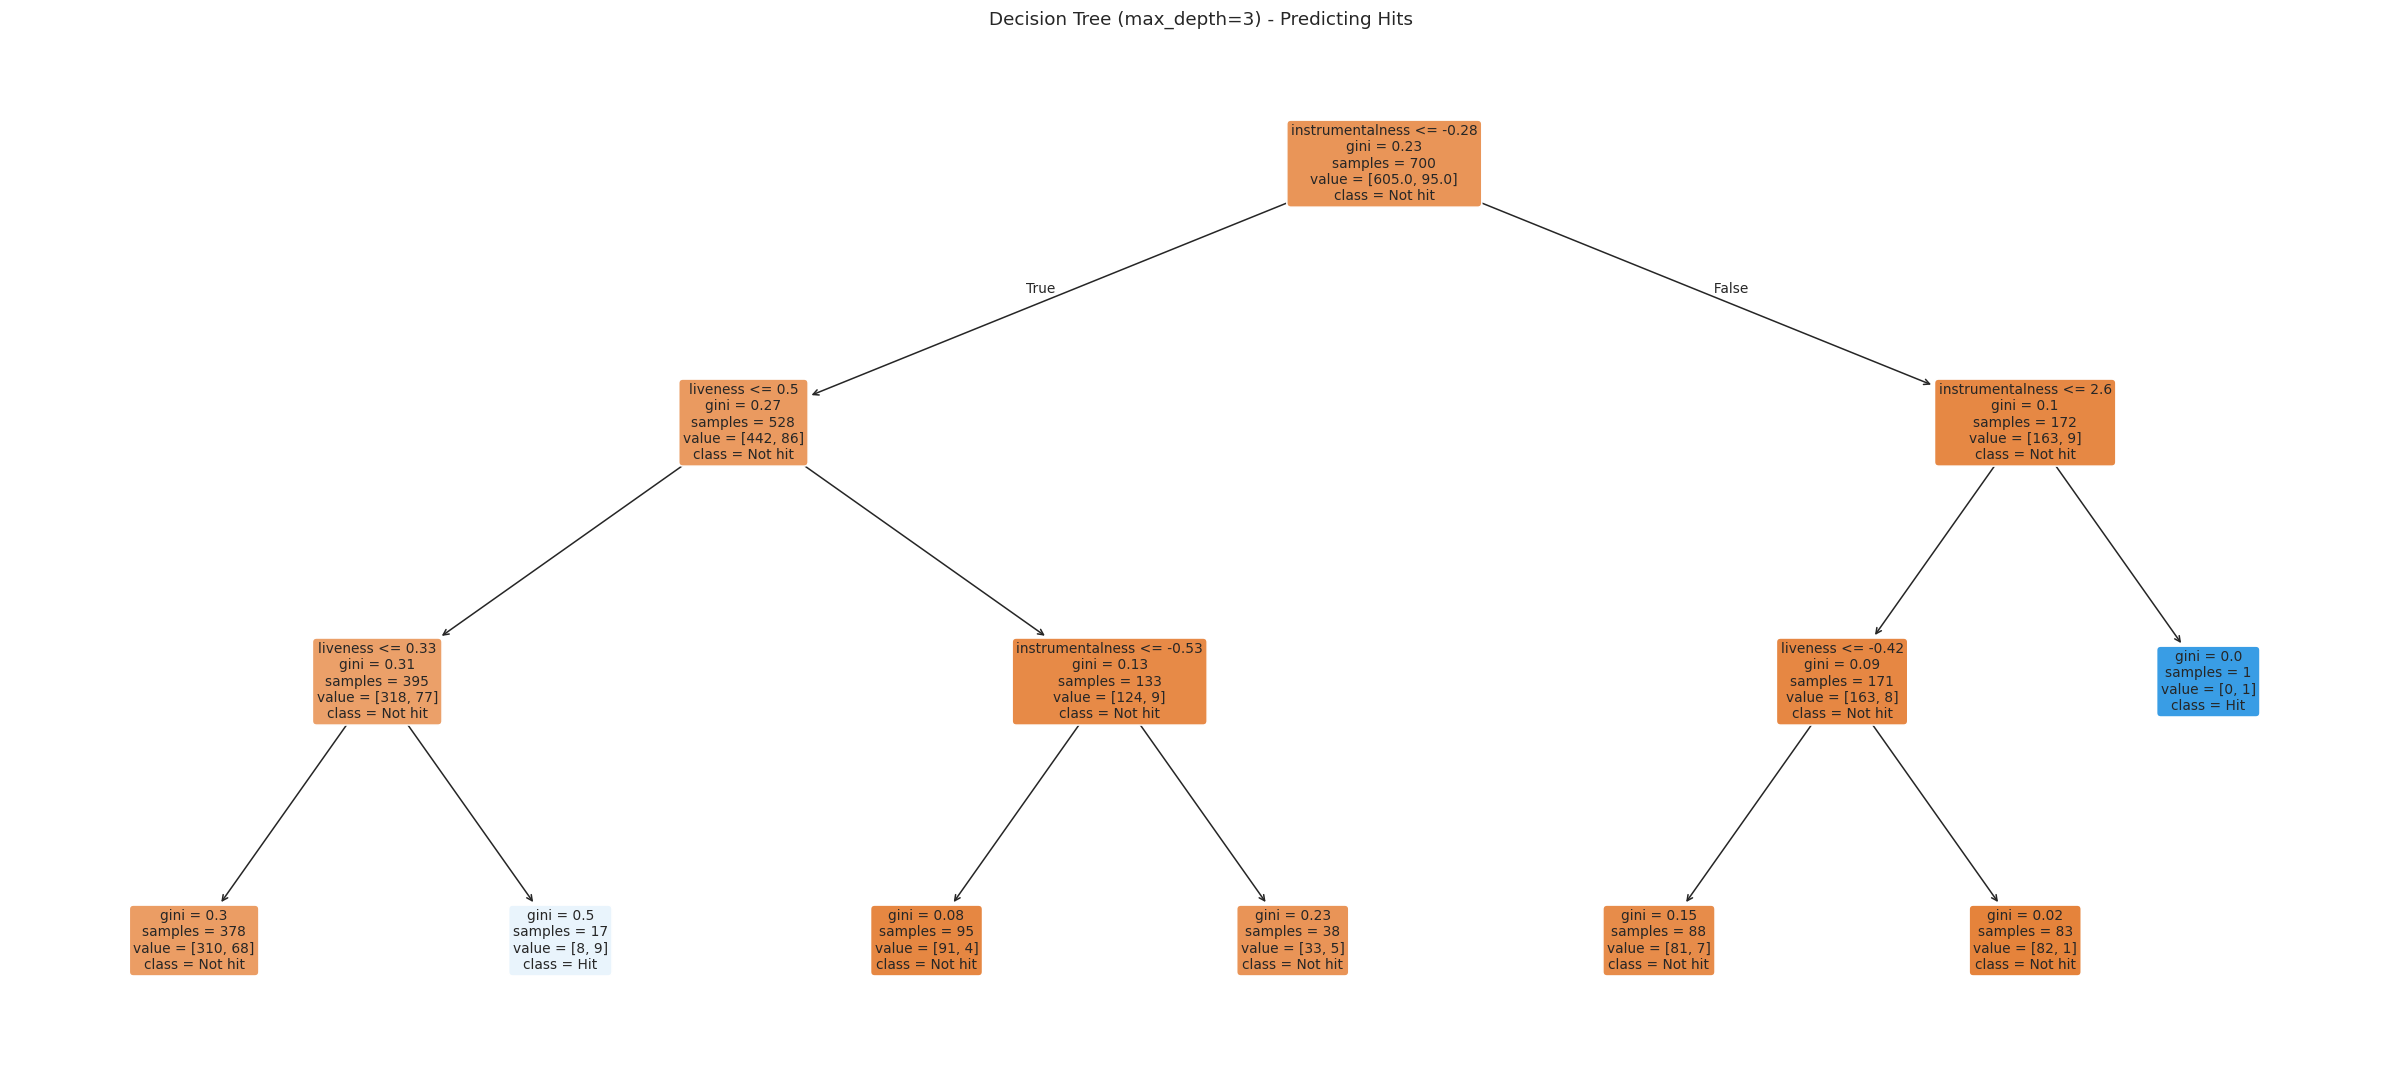

In [ ]:
tree3c = clf_fitted[("DecisionTree", "max_depth=3")]
r = clf_df[(clf_df.Model == "DecisionTree") & (clf_df.Hyperparameters == "max_depth=3")].iloc[0]
print(f"Depth-3 classification tree: Accuracy = {r.Accuracy:.4f}, Precision = {r.Precision:.4f}, "
      f"Recall = {r.Recall:.4f}, Specificity = {r.Specificity:.4f}, F1 = {r.F1:.4f}\n")
print(export_text(tree3c, feature_names=selected, decimals=2))

plt.figure(figsize=(22, 10))
plot_tree(tree3c, feature_names=selected, class_names=["Not hit", "Hit"],
      filled=True, rounded=True, fontsize=9, precision=2)
plt.title("Decision Tree (max_depth=3) - Predicting Hits")
show_fig("task3_tree_depth3.png")

#### Interpretation of the depth-3 classification tree

Features are standardized (0 = average). Class 1 = hit, class 0 = not a hit.
* Root split: instrumentalness <= -0.28 (roughly instrumentalness <= 0.08 on
  the original scale), i.e. songs with vocals versus songs with a notable
  instrumental character.
* Vocal songs (left side): the tree predicts a HIT only in one narrow niche,
  liveness between 0.33 and 0.50 (roughly 0.27 to 0.30 on the original scale).
  All other vocal songs are predicted as not a hit.
* Instrumental side: songs are predicted as not a hit unless instrumentalness is
  above 2.60 (nearly purely instrumental, roughly 0.98), which is predicted as a
  hit. This is a very small group and surprising given that instrumentalness has
  a negative correlation with popularity, so it is probably noise.
* Performance: accuracy 0.847, which is BELOW the 0.860 baseline of always
  predicting "not a hit". Precision is 0.17, recall only 0.024 (it finds 1
  of 42 real hits in the test set) and specificity is 0.98. The tree is
  therefore almost a "never a hit" rule and its splits should not be
  over-interpreted. The three features Lasso kept (instrumentalness, liveness,
  danceability) simply contain little information about hits.

### 3.6 The feature importance of the best random forest

Best random forest: max_depth=2, n_estimators=50 (Accuracy = 0.8600, Recall = 0.0000)

Feature importances:
instrumentalness   0.4033
danceability       0.3435
liveness           0.2532


None

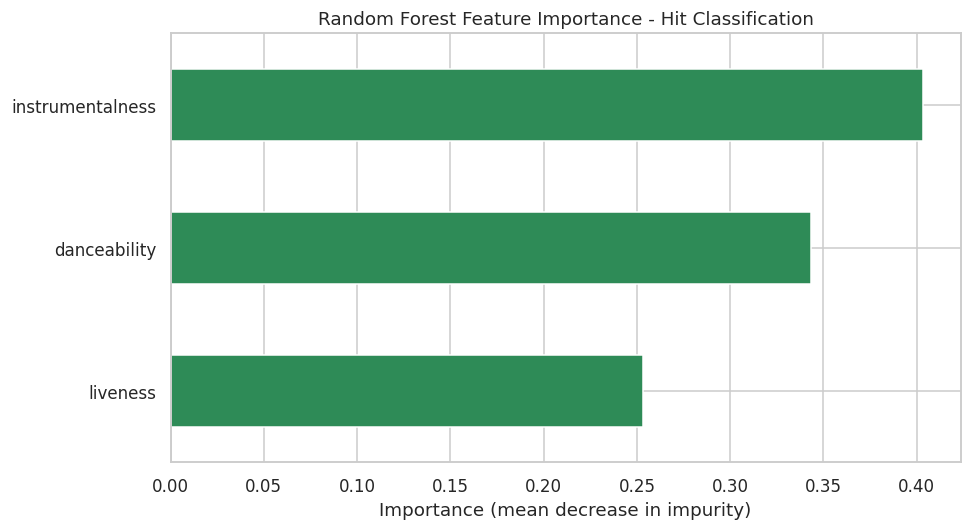

In [ ]:
best_rfc_row = clf_df[clf_df.Model == "RandomForest"].iloc[0]
best_rfc = clf_fitted[("RandomForest", best_rfc_row.Hyperparameters)]
print(f"Best random forest: {best_rfc_row.Hyperparameters} "
      f"(Accuracy = {best_rfc_row.Accuracy:.4f}, Recall = {best_rfc_row.Recall:.4f})\n")

imp_c = pd.Series(best_rfc.feature_importances_, index=selected).sort_values(ascending=False)
print("Feature importances:")
print(imp_c.to_string())

plt.figure(figsize=(9, 5))
imp_c.sort_values().plot(kind="barh", color="seagreen")
plt.title("Random Forest Feature Importance - Hit Classification")
plt.xlabel("Importance (mean decrease in impurity)")
show_fig("task3_rf_feature_importance.png")

#### Interpretation of the Task 3 models and the forest


**Model Comparison**(important warning)

* Lasso with alpha = 0.0295 kept only 3 of 140 predictors: instrumentalness
  (negative), liveness (negative) and danceability (positive). It dropped ALL
  genre dummies, even though Task 2 suggests genre matters, which limits
  every classifier that follows.
* The top 5 by accuracy are all random forests at 0.860, exactly the baseline
  accuracy of predicting 'not a hit' for every song. Their confusion matrices
  show TN = 258, FP = 0, FN = 42, TP = 0: recall, precision and F1 are all 0.
  The accuracy ranking is therefore misleading in this imbalanced problem: 24 of
  the 32 models never predict a single hit. The ties are broken with 5-fold CV
  accuracy on the training data.
* The supplementary ranking by F1 shows the models that do try to find hits.
  The best is KNN (k = 5, Minkowski p = 3) with F1 = 0.15, precision = 0.36,
  recall = 0.095 and accuracy = 0.85 (4 hits found, 7 false alarms, 38 missed).
  It is slightly less accurate than the baseline but the only kind of model that
  provides any signal. Precision and recall remain low.
* Conclusion: with these three audio features, hits cannot be predicted
  reliably. Options to improve: keep more features (a smaller Lasso alpha that
  retains genre dummies), use class weights or a lower decision threshold to raise
  recall, or evaluate with metrics such as recall, F1 or AUC rather than accuracy.


**Random Forest Feature Importance**

* The forest can only use the three selected variables: instrumentalness (0.40),
  danceability (0.34) and liveness (0.25). Importances always sum to 1, so
  these are relative shares. Because the best forest is basically a
  'never a hit' classifier, they show which variables the trees used for
  (weak) splits, not evidence that these variables produce hits.

# Conclusions
* **Popularity is hard to predict from audio features and genre alone.** The best model (Ridge, λ = 1) explains about 34% of the variance in the test set; non-linear models did worse because there are only ~6 training songs per genre.
* **Hits are even harder.** With only three features kept by Lasso, no model beats the "never a hit" baseline of 86% accuracy, so accuracy alone is misleading. F1 gives us insight.
* **Caveat on model selection:** models were ranked on the test set as the assignment requires. The reported performance is slightly optimistic. Cross-validation on the training set would be the cleaner approach.
* **Next steps:** add information not in this data (artist, release date, playlist exposure), use a smaller Lasso α so genre dummies survive, and use class weights or a lower decision threshold to improve recall.

### Tricks and mistakes I checked while writing this notebook
1. **File name:** the handout says "dataset simplifed.csv"; the real file is `dataset_simplified.csv`.
2. **141 columns:** only works if `key`, `mode`, `time_signature` and `explicit` are treated as *categorical* (`drop_first=True` avoids the dummy-variable trap). This was elusive to me for sometime. The 141 columns **include** the target `popularity` (140 predictors + 1 target).
3. **Standardize only truly numeric columns**, and disregard the dummies in the data.
4. **Data leakage in Task 3:** `popularity` defines the hit label, so it must *not* be a predictor.
5. **The hit label uses the original popularity (0–100)**, not a standardized version.
6. **Minkowski with p = 2 is identical to Euclidean**, so they would tie exactly. I decided to use p = 3 (see `MINKOWSKI_P`).
9. **Lasso feature selection uses the training data only**, so the test set cannot influence which variables are chosen.
10. **Two songs appear twice** (same `track_id` in two genres). They are valid rows and they can remain in place.
11. **Scaler is fit on all 1000 rows** Due to the fact that the assignment asks for a full 1000 × 141 standardized dataframe *before* the split. Fitting on the training rows only would be cleaner; the difference is negligible here.


## Reflection: Homework 2

### What makes a track more popular?

I strongly feel that the audio features explain little to nothing. Every correlation with popularity was weak. The strongest was **instrumentalness at -0.18**, making instrumental tracks less popular among users. Danceability was slightly positive, while duration, energy and speechiness were slightly negative. Genre seems to matter more (this is what I hypothesized as I started to work through the data), since house tracks scored high and romance tracks scored very low. Ridge with λ = 1 was the best regression model, and even it explained only **34%** of the variance.

### What did Lasso select for classification?

With α = 0.0295, Lasso kept only **3 of 140 features**:

- instrumentalness (negative)
- liveness (negative)
- danceability (positive)

It dropped every genre dummy set.

### What can we conclude from the best trees and forests?

We are not able to conclude much from the best trees and forests.

- The depth-3 popularity tree split first on energy, but its extreme leaves held only 2 to 6 songs, so they are most likely noise.
- The depth-3 hit tree scored **0.847 accuracy**, below the **0.860 baseline** of never predicting a hit. It found only 1 of 42 real hits!
- The top random forests matched the baseline exactly with zero recall.
- Their feature importances (instrumentalness 0.40, danceability 0.34, liveness 0.25) show what the trees used, not what makes a song a hit.

### Surprises and limitations

- The top 5 models by accuracy never predicted a hit, so accuracy alone was misleading with only 14% hits. I was very surprised by this, as I assumed that most of the top 5 models would do the most lifting.
- Tempo ranked 4th in forest importance despite a near-zero correlation, so impurity importance can reward noise.
- Ridge beat the non-linear models because there were only about 6 training songs per genre.
- I ranked models on the test set, which is slightly "optimistic". The data also lacks artist fame and release date, and a few rows have invalid values such as tempo = 0.
